# Environmental Sound Classification (ESC-10): an end-to-end ML pipeline

**Author:** Aime Igirimpuhwe

**Task.** Classify a 5-second audio clip into one of 10 everyday sound classes (dog, rooster, rain, sea waves, crackling fire, crying baby, sneezing, helicopter, chainsaw, clock tick). The model is deployed behind a FastAPI service with a web dashboard where a user can predict one clip, upload new labelled clips in bulk, and trigger retraining.

**Why this matters.** Sound classification is non-tabular data, and it is the building block for noise monitoring, smart-home alerts and wildlife monitoring. This notebook covers data acquisition, preprocessing, EDA, model training with several optimisation techniques, evaluation and error analysis. The same modules (`src/preprocessing.py`, `src/model.py`, `src/prediction.py`) are used by the deployed service, so what is evaluated here is what runs in production.

**Dataset.** ESC-50 (Piczak, 2015), restricted to its 10-class ESC-10 subset: 400 clips, 40 per class, from Freesound recordings.

## 1. Setup

In [1]:
import sys, json, random, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import librosa, librosa.display
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

from src.config import *
from src.preprocessing import *
from src.model import *
from src import insights

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
CLASSES = json.loads(LABELS_PATH.read_text())
print("TensorFlow", tf.__version__, "| classes:", CLASSES)

TensorFlow 2.18.1 | classes: ['chainsaw', 'clock_tick', 'crackling_fire', 'crying_baby', 'dog', 'helicopter', 'rain', 'rooster', 'sea_waves', 'sneezing']


## 2. Data acquisition and split

`src/data_acquisition.py` downloads ESC-50 and keeps the ESC-10 clips. ESC-50 ships with five predefined folds, and clips taken from the same original Freesound recording are always placed in the same fold. I split **by fold**, not by random clip:

| Split | Folds | Folder | Use |
|---|---|---|---|
| train | 1, 2, 3 | `data/train` | fit weights |
| val | 4 | `data/val` | early stopping, model selection, retraining promotion gate |
| test | 5 | `data/test` | reported once for the final model |

A random clip-level split would put near-duplicate pieces of one recording on both sides and inflate the test score. Splitting by fold avoids that. Nothing is fitted on the data during preprocessing (see section 3), so there is no leakage through normalisation statistics either.

In [2]:
counts = {}
for name, root in [("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR)]:
    _, labels = list_files(root)
    counts[name] = pd.Series(labels).value_counts()
split_table = pd.DataFrame(counts).loc[CLASSES]
split_table.loc["TOTAL"] = split_table.sum()
split_table

,train,val,test
chainsaw,24,8,8
clock_tick,24,8,8
crackling_fire,24,8,8
crying_baby,24,8,8
dog,24,8,8
helicopter,24,8,8
rain,24,8,8
rooster,24,8,8
sea_waves,24,8,8
sneezing,24,8,8


## 3. Preprocessing

Each clip goes through exactly the same steps in training, in the API and in retraining (`src/preprocessing.py`):

1. Decode, convert to **mono**, resample to **16 kHz**.
2. Fix the length to **5 s** (crop longer clips, zero-pad shorter ones), which is ESC-50's native length.
3. **Log-mel spectrogram**: 64 mel bands, FFT 1024, hop 512, converted to dB with an 80 dB floor, giving a 64x157 "image".
4. **Per-clip standardisation** (subtract the clip's own mean, divide by its own std). No dataset statistics are fitted, so nothing can leak from validation or test, and the model becomes robust to microphone gain.

**Augmentation (training data only).** Waveform level: random circular time shift (up to 1 s), gain 0.6-1.4x, additive noise at 20-35 dB SNR. This adds 3 extra copies per training clip. Spectrogram level: SpecAugment, i.e. a random frequency mask and a random time mask on every batch.

waveform: (80000,) -> log-mel: (64, 157, 1)


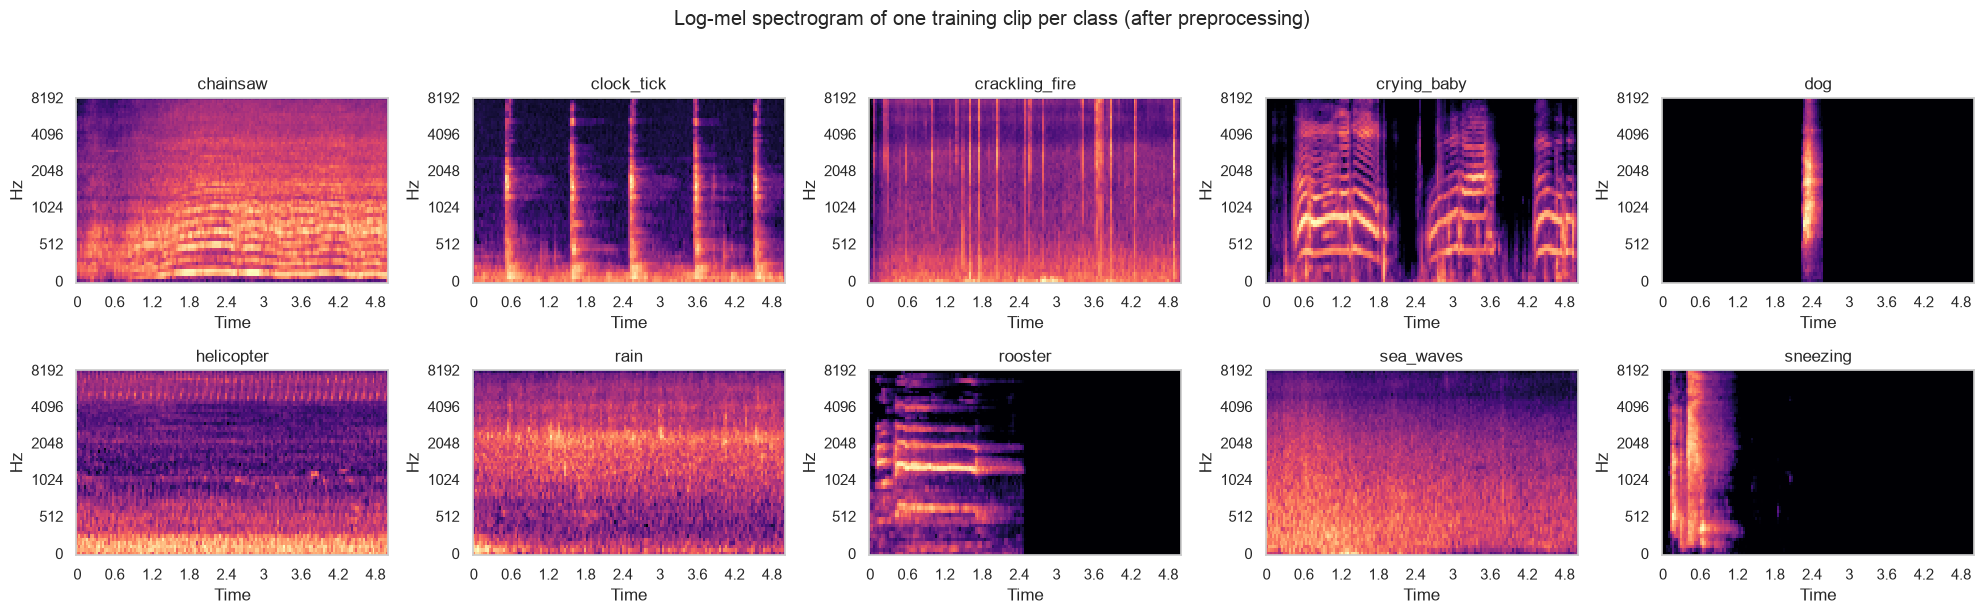

In [3]:
y = load_audio(list_files(TRAIN_DIR)[0][0])
print("waveform:", y.shape, "->", "log-mel:", log_mel(y).shape)

fig, axes = plt.subplots(2, 5, figsize=(20, 6))
for ax, cls in zip(axes.ravel(), CLASSES):
    p = list_files(TRAIN_DIR)[0][list_files(TRAIN_DIR)[1].index(cls)]
    S = log_mel(load_audio(p))[..., 0]
    librosa.display.specshow(S, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=ax, cmap="magma")
    ax.set_title(cls)
plt.suptitle("Log-mel spectrogram of one training clip per class (after preprocessing)", y=1.02)
plt.tight_layout(); plt.show()

## 4. Exploratory analysis: what does each sound look like?

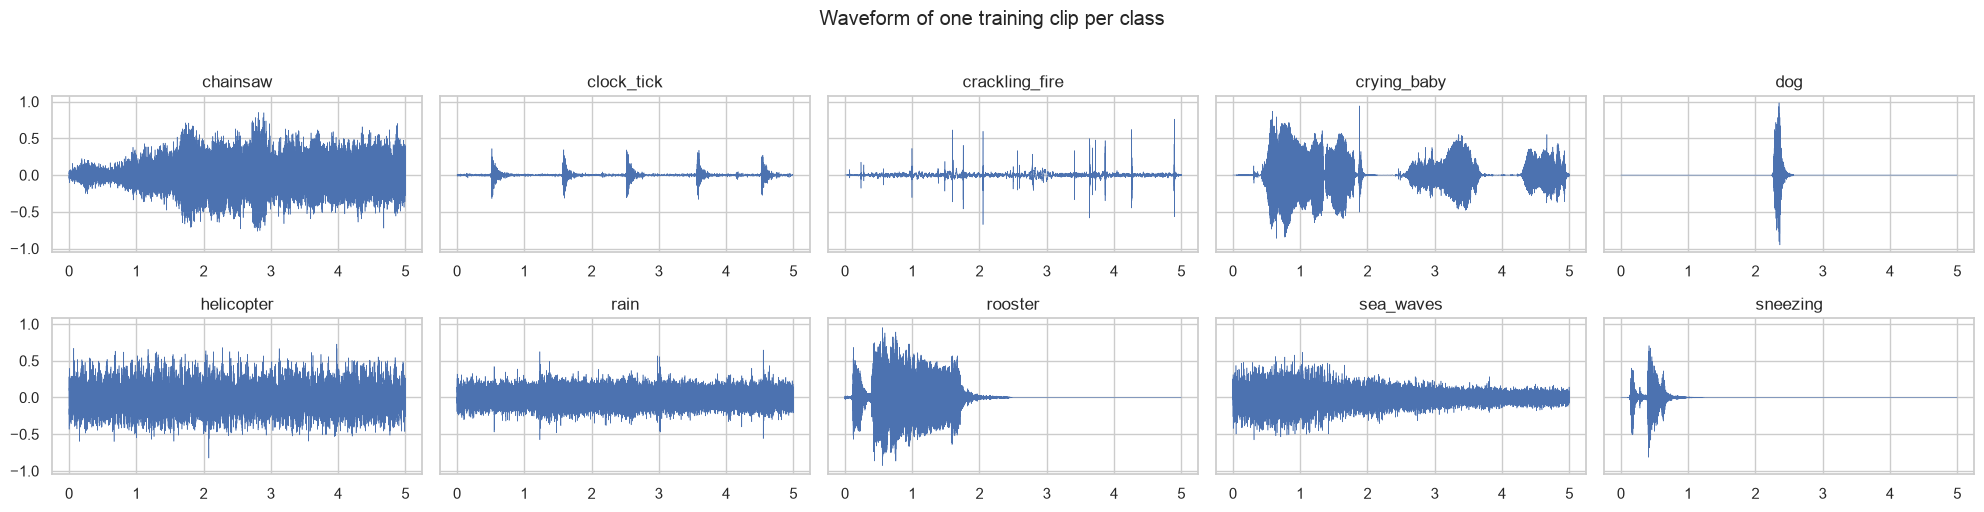

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(20, 5), sharey=True)
for ax, cls in zip(axes.ravel(), CLASSES):
    p = list_files(TRAIN_DIR)[0][list_files(TRAIN_DIR)[1].index(cls)]
    w = load_audio(p)
    ax.plot(np.arange(len(w)) / SR, w, lw=0.4)
    ax.set_title(cls)
plt.suptitle("Waveform of one training clip per class", y=1.02); plt.tight_layout(); plt.show()

In [5]:
df, _ = insights.build_insights()
feats = insights.FEATURES
df.groupby("label")[feats].mean().round(3)

,rms_energy,spectral_centroid_hz,zero_crossing_rate,spectral_rolloff_hz,active_ratio
label,,,,,
chainsaw,0.158,2368.266,0.185,4809.057,0.939
clock_tick,0.016,1871.243,0.146,3606.369,0.470
crackling_fire,0.054,1813.593,0.094,3932.203,0.791
crying_baby,0.111,2281.077,0.187,4250.204,0.638
dog,0.110,1106.376,0.090,1924.378,0.324
helicopter,0.160,1149.239,0.077,2338.692,0.952
rain,0.085,2718.659,0.259,5258.935,0.997
rooster,0.117,1143.866,0.104,1944.802,0.385
sea_waves,0.104,2036.443,0.172,4102.533,0.960


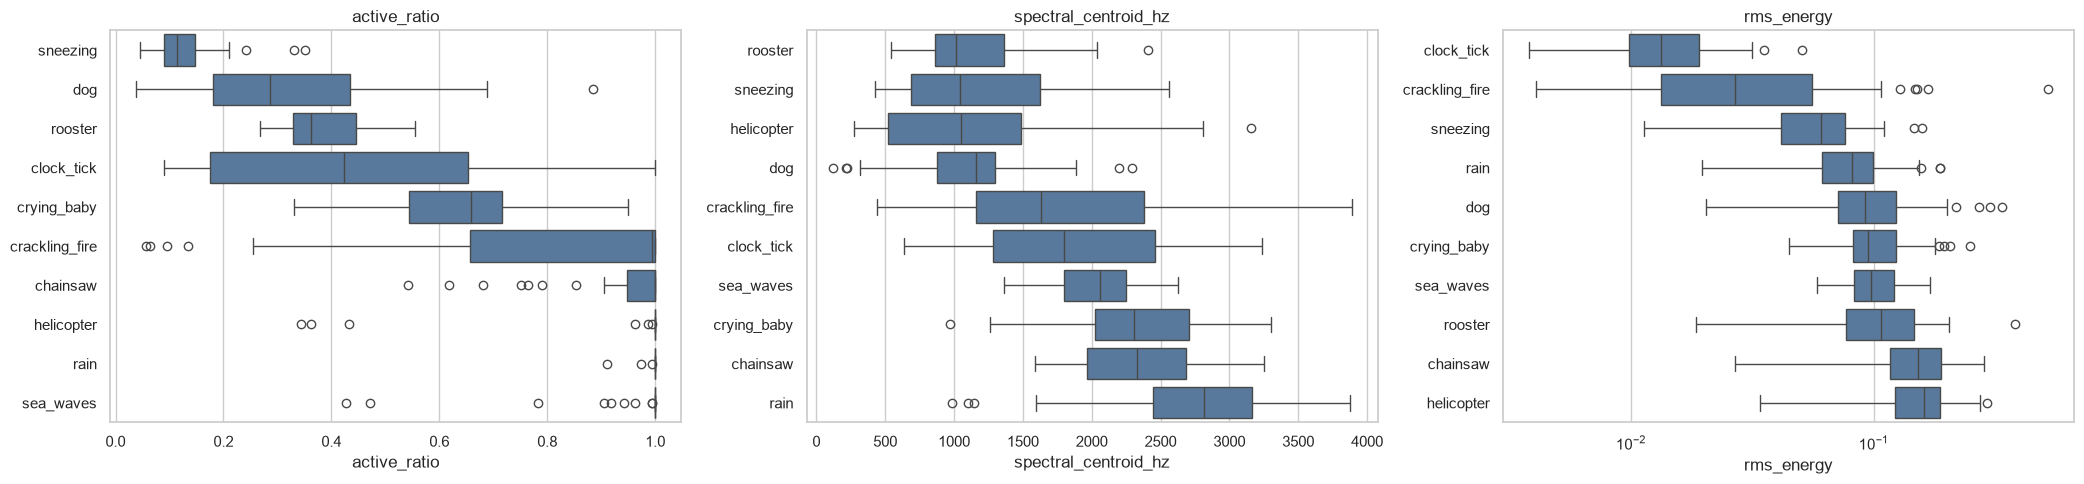

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, f in zip(axes, ["active_ratio", "spectral_centroid_hz", "rms_energy"]):
    order = df.groupby("label")[f].median().sort_values().index
    sns.boxplot(data=df, y="label", x=f, order=order, ax=ax, color="#4c78a8")
    ax.set_title(f); ax.set_ylabel("")
if True:
    axes[2].set_xscale("log")
plt.tight_layout(); plt.show()

**What the three features tell us**

1. **Active ratio separates continuous from impulsive sounds.** Rain (1.00), helicopter (0.95), sea waves (0.96) and chainsaw (0.94) are active for almost the whole clip. Sneezing (0.13), dog (0.32) and rooster (0.39) are short events padded with silence. A model can use this temporal shape alone to split the 10 classes into two groups, so the main difficulty lies inside each group.
2. **Spectral centroid separates bright from dull sounds.** Rain is the brightest (about 2.7 kHz), then chainsaw (2.4 kHz) and crying baby (2.3 kHz). Dog, rooster, helicopter and sneezing all sit between 1.1 and 1.2 kHz. Those four low-centroid classes overlap, so confusions (e.g. sneezing and dog) are most likely there.
3. **RMS energy varies by a factor of 10 across classes** (clock tick 0.016, helicopter 0.160), but it depends on how the clip was recorded, not only on the sound. The per-clip standardisation in section 3 removes this cue on purpose, which makes the model robust to microphone gain.

Also, features such as centroid and zero-crossing rate are strongly correlated (heatmap below), so they carry overlapping information about "brightness".

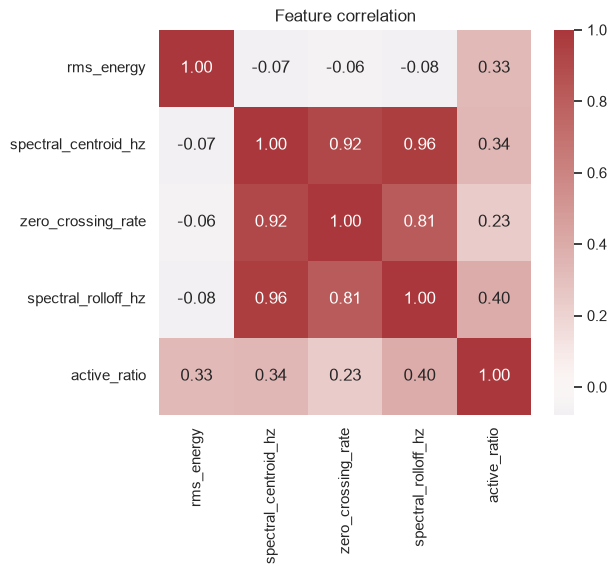

In [7]:
corr = df[feats].corr()
plt.figure(figsize=(6, 5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0); plt.title("Feature correlation"); plt.show()

## 5. Baselines

A model is only good relative to something simple. Two baselines on the test fold:

* **Majority class**: always predict one class, so accuracy is 10% with balanced classes.
* **Logistic regression on summary features**: mean and std of 20 MFCCs per clip, scaled with a scaler **fitted on the training folds only**.

In [8]:
def mfcc_stats(paths):
    out = []
    for p in paths:
        m = librosa.feature.mfcc(y=load_audio(p), sr=SR, n_mfcc=20)
        out.append(np.r_[m.mean(1), m.std(1)])
    return np.array(out)

idx = {c: i for i, c in enumerate(CLASSES)}
tr_p, tr_l = list_files(TRAIN_DIR); va_p, va_l = list_files(VAL_DIR); te_p, te_l = list_files(TEST_DIR)
Ftr, Fva, Fte = mfcc_stats(tr_p), mfcc_stats(va_p), mfcc_stats(te_p)
ytr_b, yva_b, yte_b = [np.array([idx[l] for l in L]) for L in (tr_l, va_l, te_l)]
scaler = StandardScaler().fit(Ftr)
lr = LogisticRegression(max_iter=2000, C=1.0).fit(scaler.transform(Ftr), ytr_b)
pred = lr.predict(scaler.transform(Fte))
from sklearn.metrics import accuracy_score, f1_score
baseline = {"majority class": 1 / len(CLASSES),
            "MFCC + logistic regression (accuracy)": accuracy_score(yte_b, pred),
            "MFCC + logistic regression (macro F1)": f1_score(yte_b, pred, average="macro")}
pd.Series(baseline, name="test").round(3).to_frame()

,test
majority class,0.100
MFCC + logistic regression (accuracy),0.725
MFCC + logistic regression (macro F1),0.705


## 6. Building the training sets

Features are computed once. The training folds are expanded with 3 augmented copies per clip, while validation and test stay untouched.

In [9]:
Xtr, ytr = build_features(tr_p, tr_l, CLASSES, augment_copies=3, seed=SEED)
Xva, yva = build_features(va_p, va_l, CLASSES)
Xte, yte = build_features(te_p, te_l, CLASSES)
print("train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape)

train (960, 64, 157, 1) | val (80, 64, 157, 1) | test (80, 64, 157, 1)


## 7. Model: a custom CNN on log-mel spectrograms

Four Conv-BatchNorm-ReLU-MaxPool blocks (16-32-64-96 filters), global average pooling, dropout, a 64-unit dense layer and a 10-way softmax. It is deliberately small (86k parameters) so that it trains on a CPU and fits a free cloud tier. This model is also the **pre-trained starting point** that the retraining pipeline fine-tunes.

**Optimisation techniques used:** L2 weight decay, dropout, batch normalisation, data augmentation (waveform and SpecAugment), early stopping on validation loss with best-weight restore, learning-rate reduction on plateau, and a comparison of three optimisers (Adam, SGD with Nesterov momentum, RMSprop) plus learning-rate and regularisation-strength tuning.

In [10]:
build_model(len(CLASSES)).summary()

Model: "esc10_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 157, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 157, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 157, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 157, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 78, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 78, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 78, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 39, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 39, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 39, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 19, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 19, 96)      │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 19, 96)      │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 8, 19, 96)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 9, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 96)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 86,170 (336.60 KB)

 Trainable params: 85,754 (334.98 KB)

 Non-trainable params: 416 (1.62 KB)

## 8. Experiments

Each run changes one thing from a reference configuration. Models are compared on the **validation fold**; the test fold is not touched until section 9.

In [11]:
EXPERIMENTS = {
    "e1 adam, no regularisation":        dict(l2=0,    dropout=0.0, spec=False, opt="adam",    lr=1e-3),
    "e2 adam + L2 + dropout + SpecAug":  dict(l2=1e-4, dropout=0.4, spec=True,  opt="adam",    lr=1e-3),
    "e3 sgd (nesterov) + reg":           dict(l2=1e-4, dropout=0.4, spec=True,  opt="sgd",     lr=2e-2),
    "e4 rmsprop + reg":                  dict(l2=1e-4, dropout=0.4, spec=True,  opt="rmsprop", lr=1e-3),
    "e5 adam, lr 3e-4":                  dict(l2=1e-4, dropout=0.4, spec=True,  opt="adam",    lr=3e-4),
    "e6 adam, stronger reg (l2 1e-3, drop 0.5)": dict(l2=1e-3, dropout=0.5, spec=True, opt="adam", lr=1e-3),
}
runs, models, histories = [], {}, {}
for name, cfg in EXPERIMENTS.items():
    tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
    m = compile_model(build_model(len(CLASSES), cfg["l2"], cfg["dropout"]), cfg["opt"], cfg["lr"])
    h = fit(m, Xtr, ytr, Xva, yva, epochs=80, patience=12, spec_augment=cfg["spec"])
    ev_tr, ev_va = evaluate(m, Xtr, ytr, CLASSES), evaluate(m, Xva, yva, CLASSES)
    runs.append({"experiment": name, "epochs run": len(h.history["loss"]),
                 "train acc": ev_tr["accuracy"], "val acc": ev_va["accuracy"], "val loss": ev_va["loss"],
                 "val precision": ev_va["precision_macro"], "val recall": ev_va["recall_macro"], "val F1": ev_va["f1_macro"]})
    models[name], histories[name] = m, h.history
    print(name, "-> val acc %.3f, val F1 %.3f" % (ev_va["accuracy"], ev_va["f1_macro"]))
results = pd.DataFrame(runs).set_index("experiment")
results.round(3)

e1 adam, no regularisation -> val acc 0.887, val F1 0.887


e2 adam + L2 + dropout + SpecAug -> val acc 0.938, val F1 0.937


e3 sgd (nesterov) + reg -> val acc 0.925, val F1 0.927


e4 rmsprop + reg -> val acc 0.900, val F1 0.899


e5 adam, lr 3e-4 -> val acc 0.912, val F1 0.914


e6 adam, stronger reg (l2 1e-3, drop 0.5) -> val acc 0.938, val F1 0.938


,epochs run,train acc,val acc,val loss,val precision,val recall,val F1
experiment,,,,,,,
"e1 adam, no regularisation",38,1.000,0.888,0.323,0.902,0.888,0.887
e2 adam + L2 + dropout + SpecAug,45,0.974,0.938,0.194,0.943,0.938,0.937
e3 sgd (nesterov) + reg,35,0.942,0.925,0.221,0.937,0.925,0.927
e4 rmsprop + reg,65,0.984,0.900,0.210,0.912,0.900,0.899
"e5 adam, lr 3e-4",54,0.947,0.912,0.349,0.926,0.912,0.914
"e6 adam, stronger reg (l2 1e-3, drop 0.5)",64,0.982,0.938,0.197,0.943,0.938,0.938


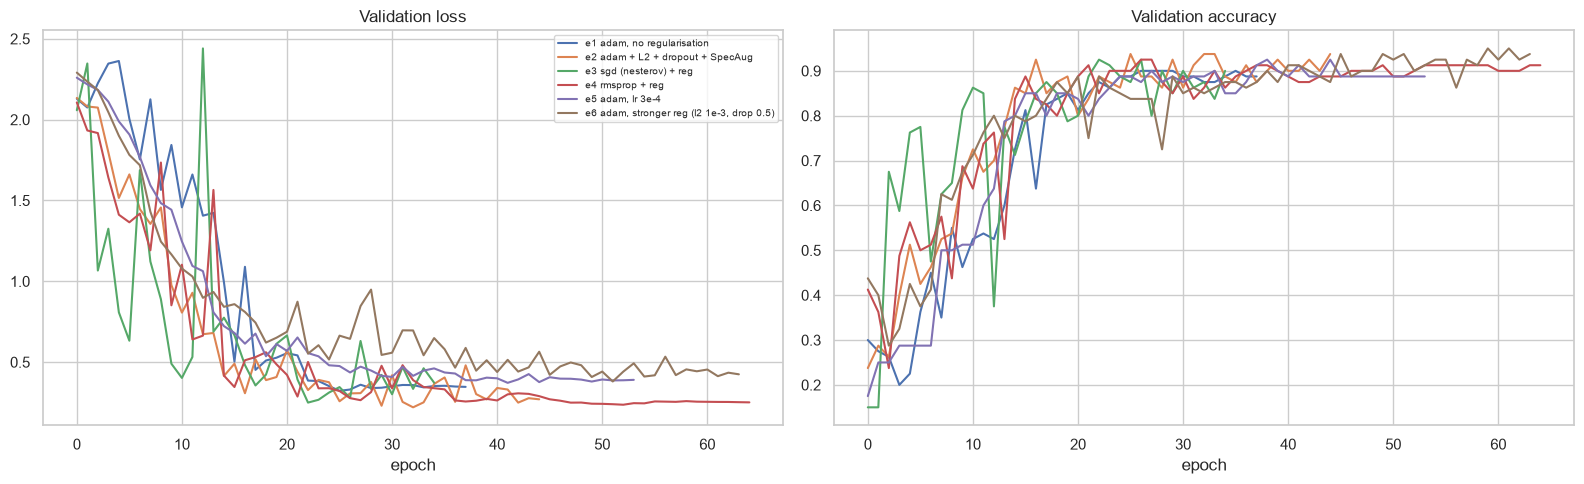

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, h in histories.items():
    axes[0].plot(h["val_loss"], label=name); axes[1].plot(h["val_accuracy"], label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation accuracy")
for a in axes: a.set_xlabel("epoch")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**My observations**

* **Regularisation was the biggest single gain.** With no regularisation (e1) the model memorises the training set (train accuracy 100%, validation 88.8%, validation loss 0.32). Adding L2, dropout and SpecAugment (e2) lifts validation accuracy to 93.8% and halves the gap between train and validation.
* **Optimiser matters less than regularisation.** Adam (e2, F1 0.937) and SGD with Nesterov momentum (e3, F1 0.927) end close together; SGD stopped earlier with lower training accuracy (94.2%), meaning it is under-fitted rather than over-fitted. RMSprop (e4, F1 0.899) was the weakest.
* **A lower learning rate (e5, 3e-4) did not help** (validation loss 0.35, higher than e2's 0.19): the model was still improving slowly when early stopping ended it.
* **Stronger regularisation (e6) gave the best validation F1 (0.938), but only by 0.001 over e2.** With 160 validation clips, one clip is 0.6 points, so e2 and e6 are statistically tied. I still pick e6 by the rule I fixed in advance (highest validation F1), and I report that honestly rather than choosing after seeing the test fold.

## 9. Final model on the held-out test fold

The experiment with the best validation macro-F1 is selected, and its test-fold results are reported **once**. Reported metrics: accuracy, loss, macro precision, macro recall, macro F1, plus a per-class report, confusion matrix and ROC curves.

In [13]:
best_name = results["val F1"].idxmax()
best = models[best_name]
print("Selected:", best_name)
final = evaluate(best, Xte, yte, CLASSES)
pd.Series({k: final[k] for k in ["accuracy", "loss", "precision_macro", "recall_macro", "f1_macro"]}, name="test").round(4).to_frame()

Selected: e6 adam, stronger reg (l2 1e-3, drop 0.5)


,test
accuracy,0.8625
loss,0.3607
precision_macro,0.8908
recall_macro,0.8625
f1_macro,0.8684


In [14]:
probs = best.predict(Xte, verbose=0); pred = probs.argmax(1)
print(classification_report(yte, pred, target_names=CLASSES, digits=3))

                precision    recall  f1-score   support

      chainsaw      1.000     0.750     0.857         8
    clock_tick      0.875     0.875     0.875         8
crackling_fire      0.750     0.750     0.750         8
   crying_baby      1.000     1.000     1.000         8
           dog      0.700     0.875     0.778         8
    helicopter      0.583     0.875     0.700         8
          rain      1.000     0.875     0.933         8
       rooster      1.000     1.000     1.000         8
     sea_waves      1.000     0.875     0.933         8
      sneezing      1.000     0.750     0.857         8

      accuracy                          0.863        80
     macro avg      0.891     0.863     0.868        80
  weighted avg      0.891     0.863     0.868        80



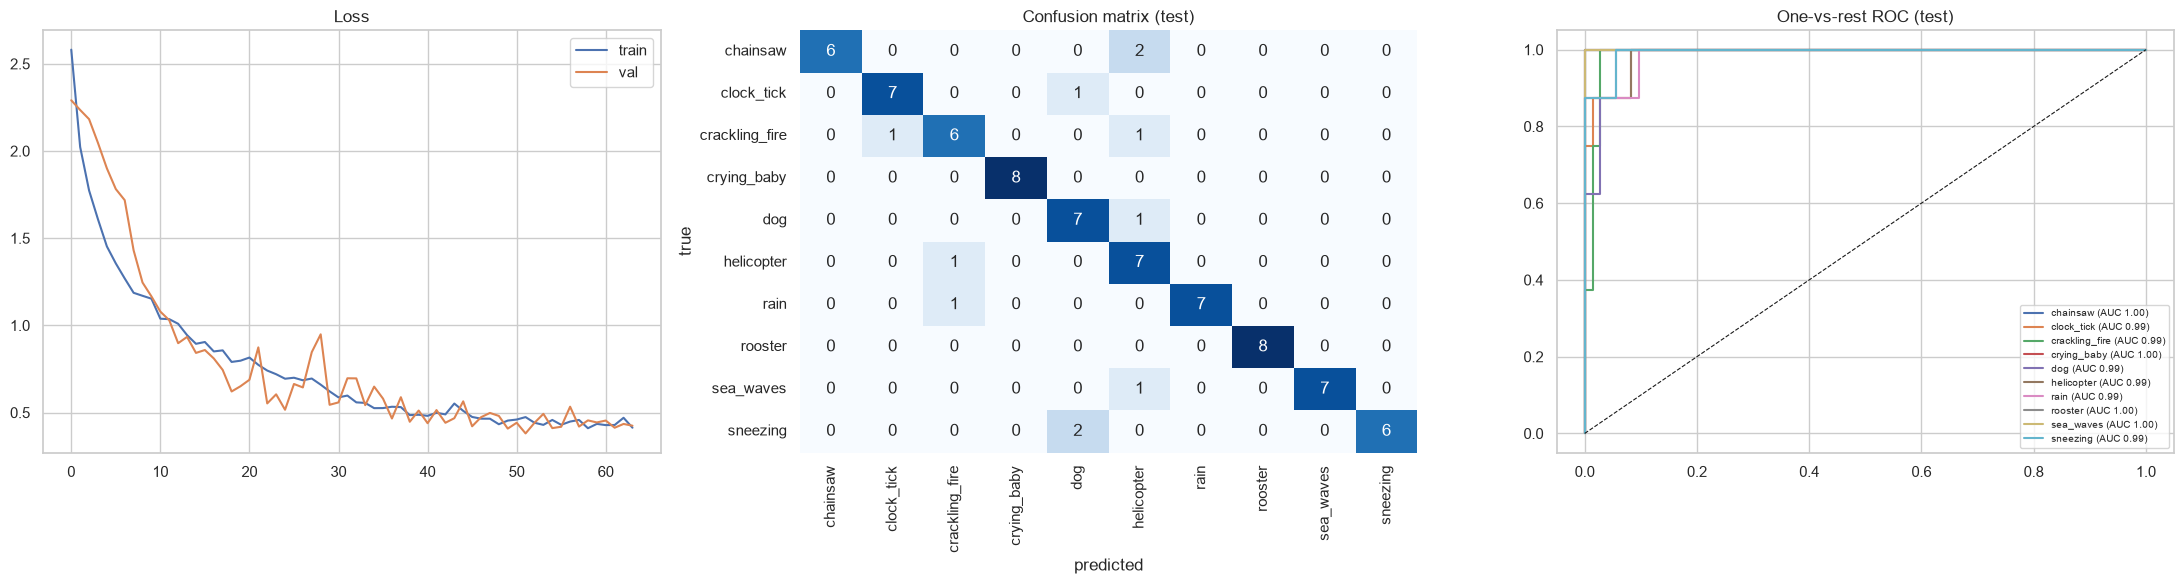

In [15]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
h = histories[best_name]
axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="val"); axes[0].set_title("Loss"); axes[0].legend()
axes[0].plot([], [])
cm = np.array(final["confusion_matrix"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], cbar=False)
axes[1].set_title("Confusion matrix (test)"); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true")
Y = label_binarize(yte, classes=range(len(CLASSES)))
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Y[:, i], probs[:, i]); axes[2].plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.2f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=0.8); axes[2].set_title("One-vs-rest ROC (test)"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [16]:
off = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j] > 0]
pd.DataFrame(sorted(off, key=lambda t: -t[2]), columns=["true", "predicted as", "count"]).head(8)

,true,predicted as,count
0,chainsaw,helicopter,2
1,sneezing,dog,2
2,clock_tick,dog,1
3,crackling_fire,clock_tick,1
4,crackling_fire,helicopter,1
5,dog,helicopter,1
6,helicopter,crackling_fire,1
7,rain,crackling_fire,1


**My observations on the test fold**

* **Headline: 86.3% accuracy, macro F1 0.868, loss 0.361** (69 of 80 clips correct). The MFCC + logistic regression baseline reaches 72.5% accuracy and the majority baseline 10%, so the CNN is a clear improvement (+13.8 points).
* **Validation 93.8% vs test 86.3%.** The 7.5 point drop is expected: I selected the model on validation, which makes that score slightly optimistic, and the test fold has only 80 clips (about +/- 7.5 points at 95% confidence). I treat 86% as the honest estimate.
* **Easy classes:** crying baby and rooster are perfect (F1 1.00), and rain and sea waves are at 0.93.
* **Hard classes:** helicopter has the lowest precision (0.58) because it absorbs errors from other classes (2 chainsaws, 1 sea wave and 1 dog were labelled helicopter). Both chainsaw and helicopter are steady, low-pitched engine-like noises, which fits the feature analysis. Crackling fire (F1 0.75) is confused with clock tick and helicopter, and sneezing is mistaken for dog twice, which also matches the overlap of short, low-centroid sounds found in section 4.
* **Next steps if more accuracy is needed:** more labelled clips per class (the retraining pipeline in this project exists for exactly that), or a pre-trained audio embedding such as YAMNet as the starting point.

## 10. Save the model and a prediction function

The selected model is saved as `models/esc10_cnn.h5` (the base model, never overwritten: retraining writes new versions under `models/versions/` and moves a pointer, `models/current.json`). The label list is saved next to it. `src/prediction.py` loads them and predicts from any audio file.

In [17]:
MODEL_DIR.mkdir(exist_ok=True)
best.save(BASE_MODEL)
LABELS_PATH.write_text(json.dumps(CLASSES))
json.dump({"selected": best_name, "test": {k: final[k] for k in ["accuracy","loss","precision_macro","recall_macro","f1_macro"]},
           "per_class": final["per_class"], "confusion_matrix": final["confusion_matrix"]}, open(MODEL_DIR / "base_metrics.json", "w"), indent=1)
results.round(4).to_csv(MODEL_DIR / "experiments.csv")
(CURRENT_POINTER).unlink(missing_ok=True)
print("saved", BASE_MODEL, f"({BASE_MODEL.stat().st_size/1e6:.2f} MB)")

saved /Users/igaime/Development/ALU/2026/MLOP_Summative/models/esc10_cnn.h5 (1.12 MB)


In [18]:
from src.prediction import Predictor
predictor = Predictor()
sample = te_p[7]
print("true:", te_l[7])
predictor.predict(sample)

true: chainsaw


{'label': 'helicopter',
 'confidence': 0.9606616497039795,
 'top': [{'label': 'helicopter', 'confidence': 0.9606616497039795},
  {'label': 'chainsaw', 'confidence': 0.03220720589160919},
  {'label': 'sea_waves', 'confidence': 0.005558748263865709}],
 'model_version': 0}

In [19]:
ok = sum(predictor.predict(p)["label"] == l for p, l in zip(te_p, te_l))
print(f"Prediction function reproduces test accuracy: {ok}/{len(te_p)} = {ok/len(te_p):.4f} (notebook: {final['accuracy']:.4f})")

Prediction function reproduces test accuracy: 69/80 = 0.8625 (notebook: 0.8625)


## 11. Limitations

* **Small test set.** 80 clips (8 per class) means one clip is 1.25 points of accuracy; treat differences of a point or two as noise.
* **Closed set.** The model always outputs one of 10 classes. A dishwasher or a car horn will be labelled as one of them, sometimes with high confidence.
* **Silence padding.** ESC-50 pads short events with digital silence, and the model may partly use the silence as a cue (see the active-ratio analysis). Uploaded clips are padded the same way so the behaviour is consistent, but this can differ from real continuous recordings.
* **Recording conditions.** All training clips are Freesound recordings; microphones and rooms in the wild will differ.

## 12. References

* Piczak, K. J. (2015). ESC: Dataset for Environmental Sound Classification. *Proceedings of the 23rd ACM International Conference on Multimedia*.
* Park, D. S. et al. (2019). SpecAugment: A simple data augmentation method for automatic speech recognition. *Interspeech*.